<a href="https://colab.research.google.com/github/charliecapretta/NBA-Prediction-Project/blob/main/EDANotebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("/content/nba_player_seasons_clean.csv")

data.head()

,Player,WS,G,MP,Season,Age,Team,GS,AS,FG,...,TOVPG,FGAPG,2PAPG,3PAPG,FTAPG,ORPG,DRPG,Player_Key,All_NBA,All_NBA_Team
0,James Harden,15.2,78,2867,2018-19,29,HOU,78,1,843,...,4.961538,24.474359,11.294872,13.179487,11.000000,0.846154,5.794872,james harden,1,1
1,Rudy Gobert,14.4,81,2577,2018-19,26,UTA,80,0,476,...,1.604938,8.790123,8.790123,0.000000,6.444444,3.814815,9.037037,rudy gobert,1,3
2,Giannis Antetokounmpo,14.4,72,2358,2018-19,24,MIL,72,1,721,...,3.722222,17.319444,14.500000,2.819444,9.527778,2.208333,10.263889,giannis antetokounmpo,1,1
3,Damian Lillard,12.1,80,2838,2018-19,28,POR,80,1,681,...,2.650000,19.162500,11.125000,8.037500,6.412500,0.850000,3.787500,damian lillard,1,2
4,Paul George,11.9,77,2841,2018-19,28,OKC,77,1,707,...,2.662338,20.961039,11.129870,9.831169,7.012987,1.363636,6.792208,paul george,1,1


In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
WS,1373.0,4.916533,2.299679,2.100000,3.200000,4.300000,6.000000,17.000000
G,1373.0,66.417334,10.672567,20.000000,60.000000,68.000000,74.000000,84.000000
MP,1373.0,1839.810634,484.700855,658.000000,1461.000000,1864.000000,2193.000000,3036.000000
Age,1373.0,26.653314,3.988776,19.000000,24.000000,26.000000,29.000000,40.000000
GS,1373.0,44.940277,25.533850,0.000000,21.000000,51.000000,67.000000,83.000000
AS,1373.0,0.133285,0.340006,0.000000,0.000000,0.000000,0.000000,1.000000
FG,1373.0,340.176256,153.792090,73.000000,220.000000,307.000000,440.000000,860.000000
FGA,1373.0,703.467589,324.590430,107.000000,447.000000,637.000000,913.000000,1909.000000
2P,1373.0,242.939548,136.555753,15.000000,137.000000,214.000000,329.000000,803.000000
2PA,1373.0,442.051712,246.511337,30.000000,253.000000,385.000000,593.000000,1393.000000


## Tesing the Features to build the clusering and prediction models. For features I belive assists, points, and 3pt% will have high correlation to ALL NBA

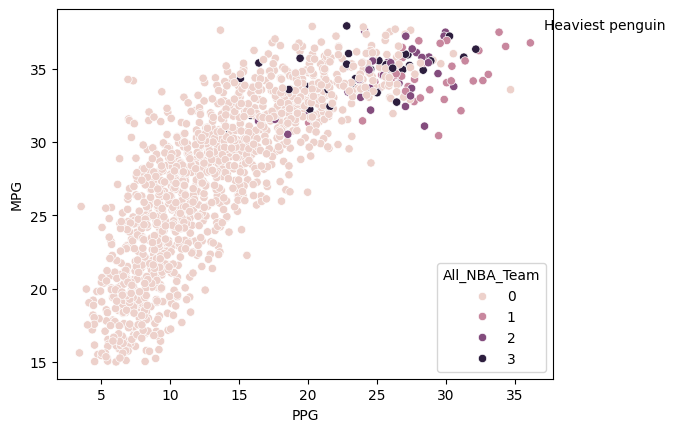

In [15]:
sns.scatterplot(data=data, x="PPG", y="MPG", hue = "All_NBA_Team")

heaviest = data.loc[data["PPG"].idxmax()]

plt.annotate("Heaviest penguin",
             xy=(heaviest["PPG"], heaviest["MPG"]),
             xytext=(10, 10), textcoords="offset points")


plt.show()

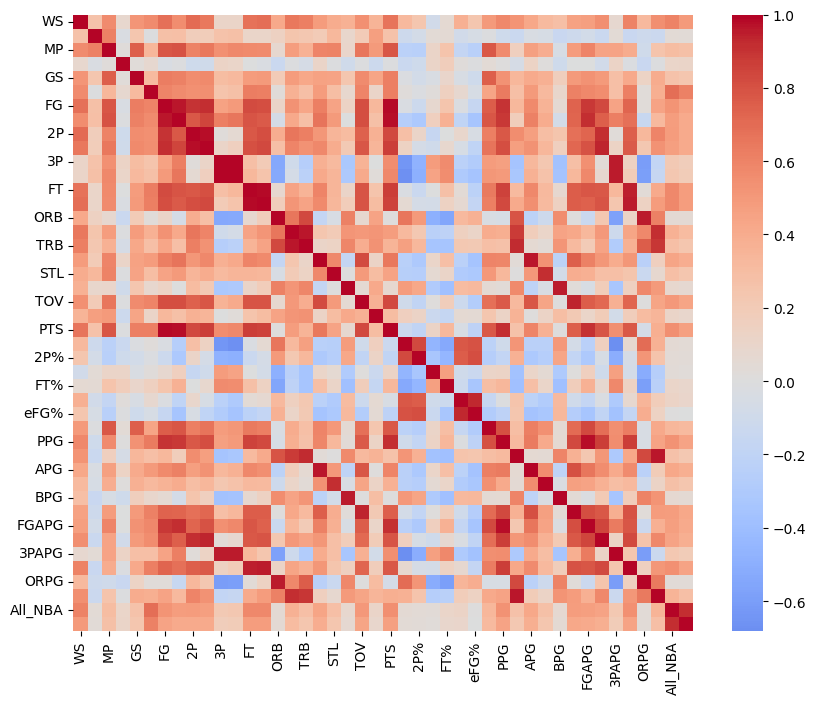

,All_NBA
All_NBA,1.000000
All_NBA_Team,0.920392
AS,0.685429
WS,0.600093
FTA,0.575024
FT,0.573820
PTS,0.549867
FTAPG,0.542437
PPG,0.530972
FG,0.527197


In [9]:
numericCols = data.select_dtypes("number")
corrMatrix = numericCols.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corrMatrix, cmap="coolwarm", center=0)
plt.show()

corrMatrix["All_NBA"].sort_values(ascending=False)  # one column vs. all others



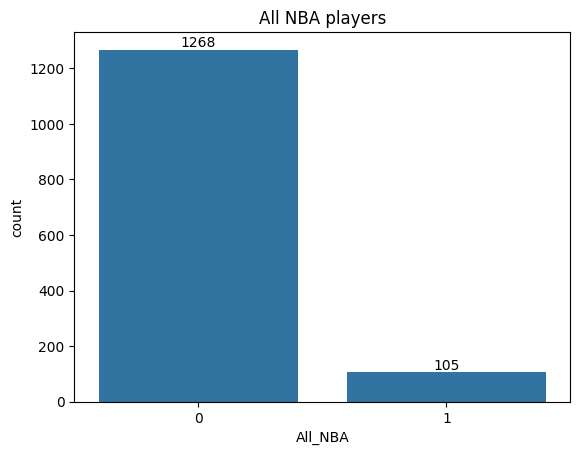

In [13]:
ax = sns.countplot(data=data, x="All_NBA")
ax.bar_label(ax.containers[0])   # prints the count above each bar
plt.title("All NBA players")
plt.show()

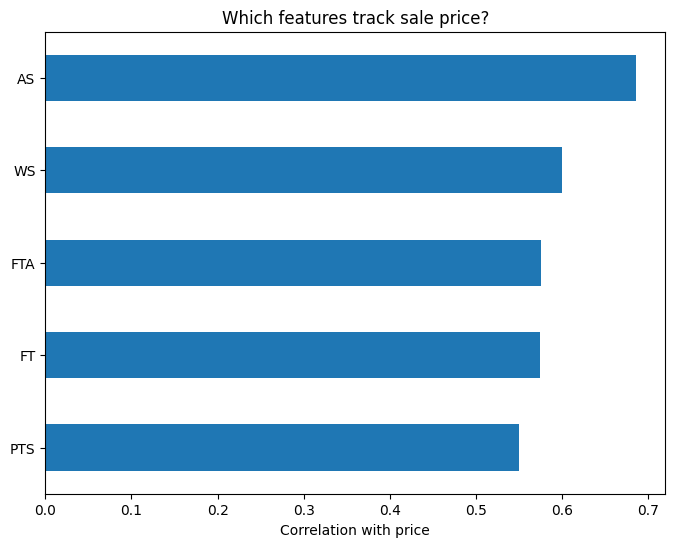

In [14]:
featureCols = ["AS", "WS", "FTA", "FT", "PTS"]

targetCorr = data[featureCols].corrwith(data["All_NBA"]).sort_values()

targetCorr.plot(kind="barh", figsize=(8, 6))
plt.xlabel("Correlation with price")
plt.title("Which features track sale price?")
plt.show()